# ABL1: faithfulness results

In [1]:
from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_DATASETS,
    REAL_WORLD_RESULTS,
    REAL_WORLD_TARGET_COLORS,
    calculate_stats_by_method_target,
    combine_and_calculate_variance,
    compute_correlation_summary,
    compute_k_effect,
    create_grouped_boxplot,
    load_raw_data,
    load_raw_data_all_thres,
    pair_xai_methods,
    plot_boxplot_grid_by_model,
    plot_correlation_heatmap,
    plot_k_effect_bars,
    plot_negative_deviations,
    plot_std_by_method_target,
    process_fidelity_df,
)

In [2]:
DATASET = 'ABL1'
FOLDER, TARGET_NAME = REAL_WORLD_DATASETS[DATASET]
BASE_DIR = REAL_WORLD_RESULTS / FOLDER
OUTPUT_DIR = BASE_DIR / 'result_plots'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
fid_df = process_fidelity_df(load_raw_data(BASE_DIR, TARGET_NAME))
fid_all_thres_df = process_fidelity_df(load_raw_data_all_thres(BASE_DIR, TARGET_NAME))
target_data = {DATASET: fid_df}

abl1: 23,975 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
20,550 rows | {'faithful': 11294, 'unfaithful': 9256} | normalized_fid in [-1.000, 1.000]


abl1: 215,775 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
184,950 rows | {'faithful': 97527, 'unfaithful': 87423} | normalized_fid in [-1.000, 1.000]


## Fid+ by xAI method and model

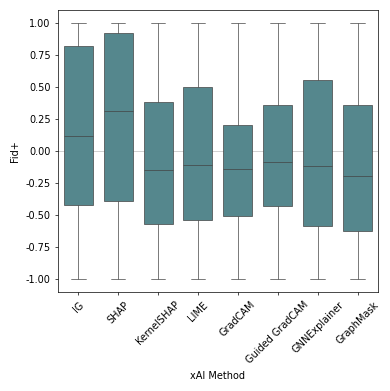

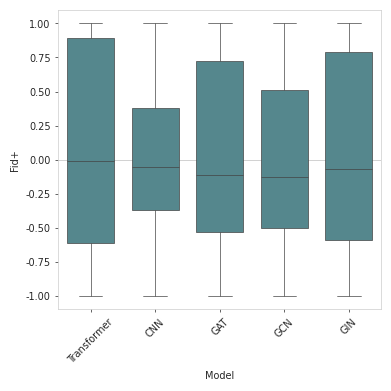

In [4]:
for group_col in ('explanation_method', 'model'):
    create_grouped_boxplot(target_data, value_col='normalized_fid', group_col=group_col, figsize=(4, 4),
                           target_colors=REAL_WORLD_TARGET_COLORS, output_dir=OUTPUT_DIR)

## xAI methods per model

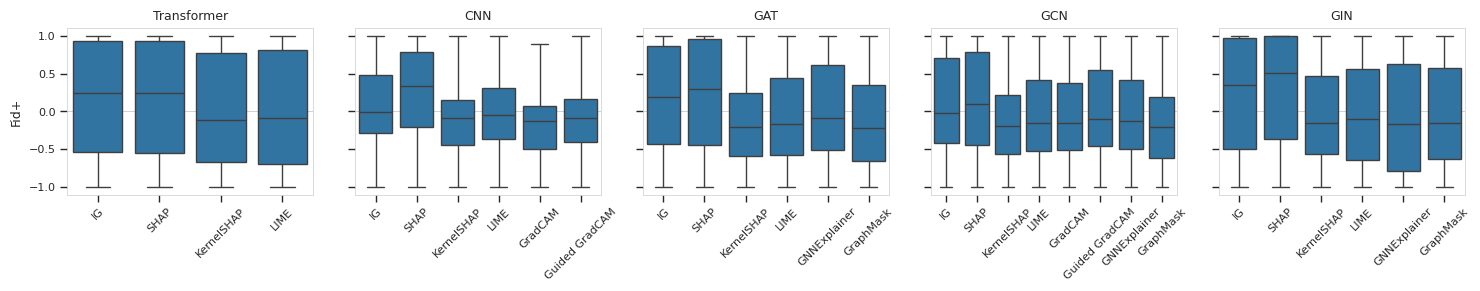

In [5]:
plot_boxplot_grid_by_model(fid_df, output_dir=OUTPUT_DIR);

## Summary table & standard deviation

In [6]:
variance_df = combine_and_calculate_variance(target_data)
variance_df

,model,explanation_method,target,n,mean,median,std,var
25,GIN,SHAP,ABL1,685,0.253,0.511,0.724,0.523
22,GIN,IG,ABL1,685,0.177,0.349,0.735,0.540
5,CNN,SHAP,ABL1,685,0.242,0.339,0.613,0.376
11,GAT,SHAP,ABL1,685,0.188,0.293,0.721,0.520
26,Transformer,IG,ABL1,685,0.137,0.246,0.744,0.554
29,Transformer,SHAP,ABL1,685,0.135,0.238,0.749,0.562
8,GAT,IG,ABL1,685,0.142,0.190,0.707,0.499
19,GCN,SHAP,ABL1,685,0.119,0.092,0.687,0.471
2,CNN,IG,ABL1,685,0.059,-0.004,0.596,0.355
16,GCN,IG,ABL1,685,0.083,-0.020,0.661,0.437


In [7]:
calculate_stats_by_method_target(target_data)

,explanation_method,target,n,median,std,var
0,GNNExplainer,ABL1,2055,-0.122379,0.684171,0.468089
1,GradCAM,ABL1,1370,-0.145901,0.601439,0.361729
2,GraphMask,ABL1,2055,-0.196561,0.670457,0.449513
3,Guided GradCAM,ABL1,1370,-0.088649,0.608732,0.370555
4,IG,ABL1,3425,0.113728,0.691631,0.478353
5,KernelSHAP,ABL1,3425,-0.152831,0.654894,0.428886
6,LIME,ABL1,3425,-0.109495,0.666669,0.444448
7,SHAP,ABL1,3425,0.308931,0.702043,0.492865


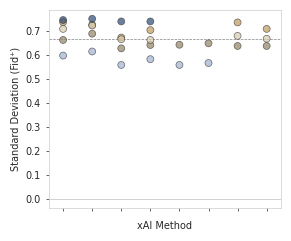

In [8]:
plot_std_by_method_target(variance_df, output_dir=OUTPUT_DIR);

## Parameter k analysis

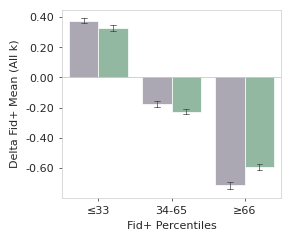

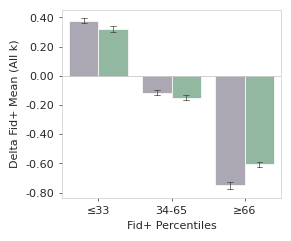

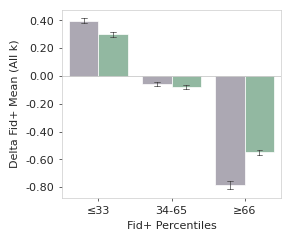

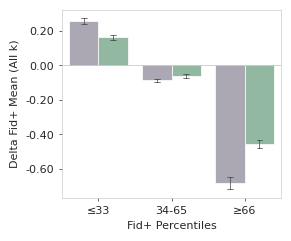

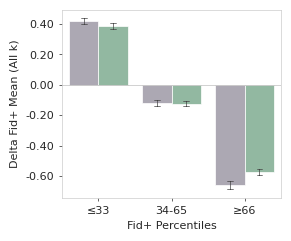

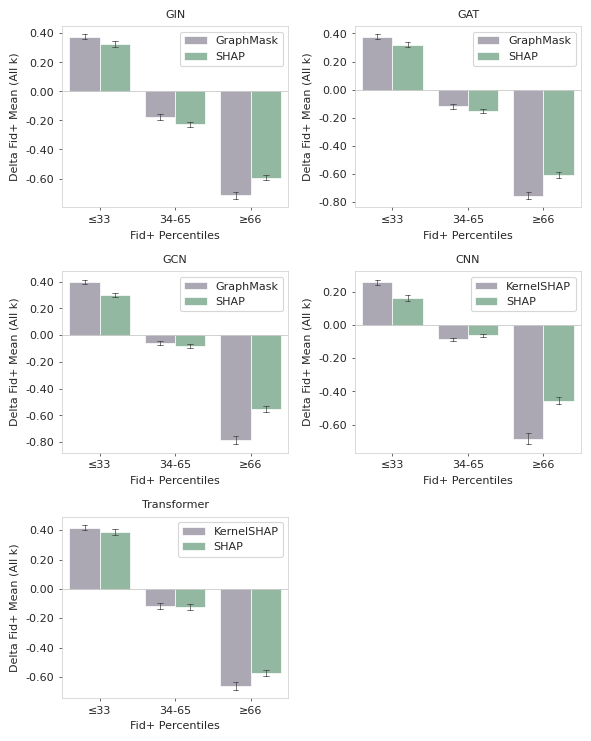

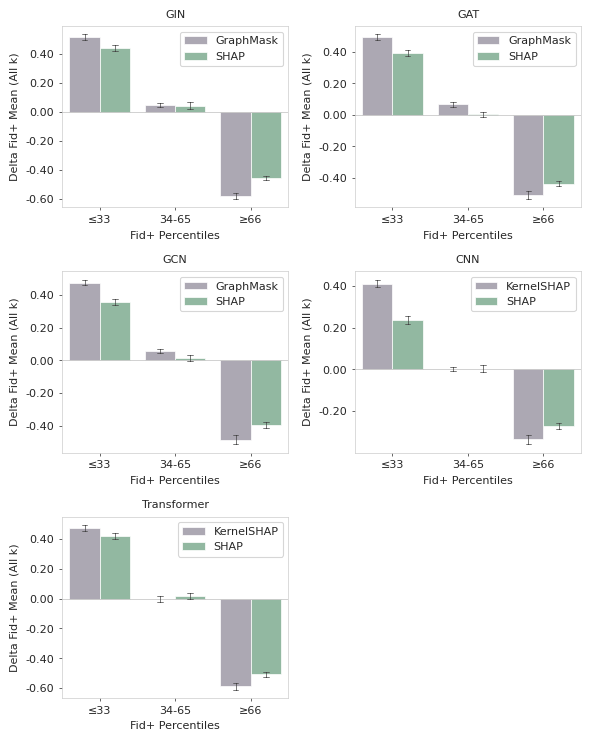

In [9]:
k_effect_df = compute_k_effect(fid_all_thres_df)
plot_k_effect_bars(k_effect_df, OUTPUT_DIR)

### Negative deviation

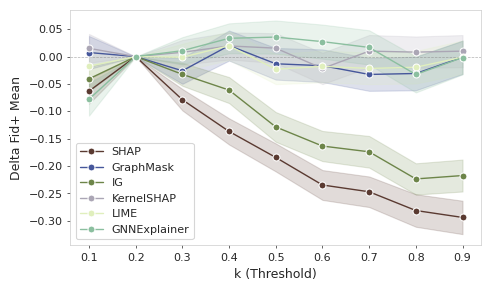

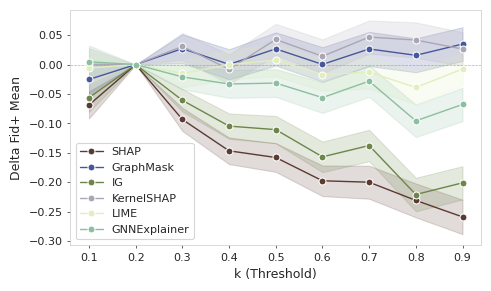

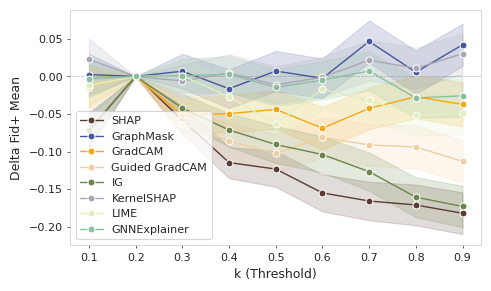

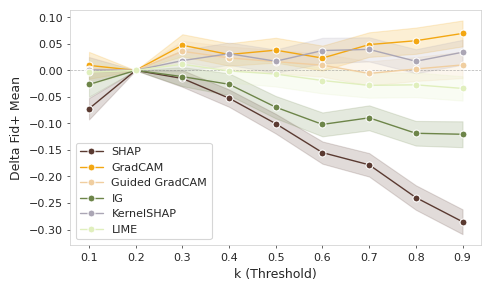

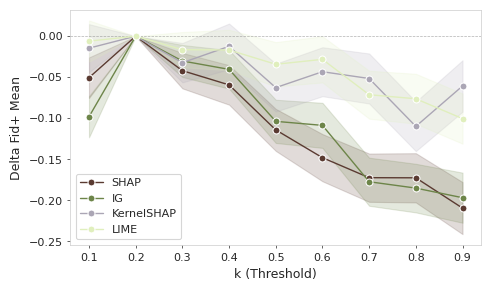

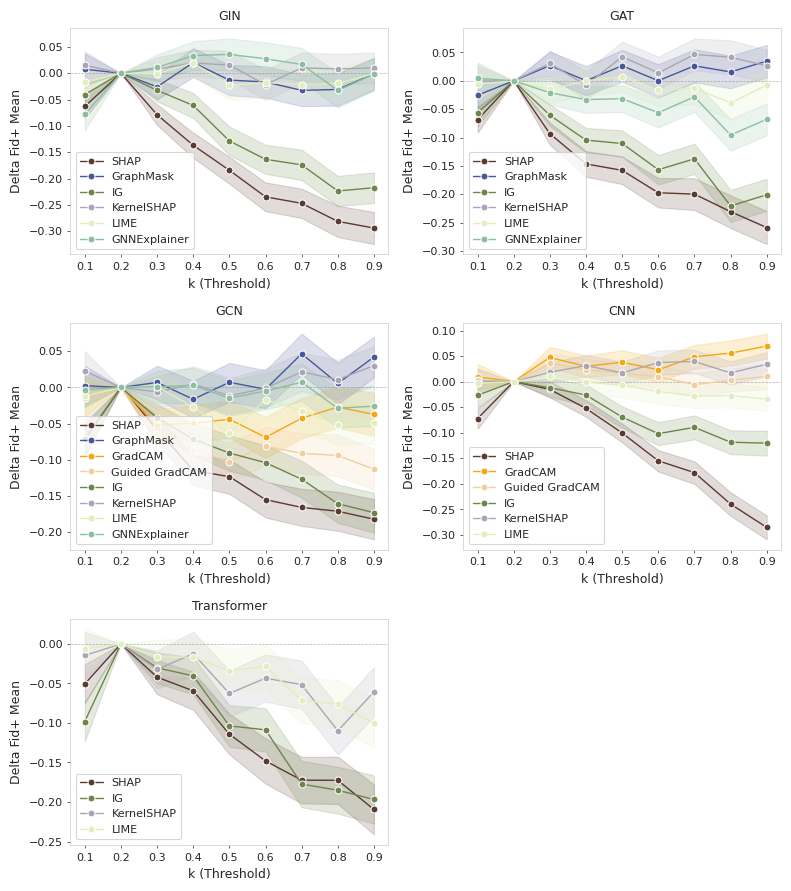

In [10]:
plot_negative_deviations(k_effect_df, OUTPUT_DIR)

## IG vs SHAP agreement

Per-molecule Normalized Fid+ of `integrated_gradients` and `shap_sampling` (same model, smiles, data split) are paired and correlated, to see whether "hard to explain" molecules are intrinsic to the molecule/model or an artifact of the xAI method.

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,ABL1,CNN,685,0.604097,2.318526e-69,0.600094,3.086479e-68
1,ABL1,GAT,685,0.756406,4.915307e-128,0.761881,6.003227e-131
2,ABL1,GCN,685,0.695880,2.752381e-100,0.692609,5.521774e-99
3,ABL1,GIN,685,0.748891,3.682249e-124,0.776364,4.759147e-139
4,ABL1,Transformer,685,0.757001,2.389893e-128,0.785407,2.013617e-144


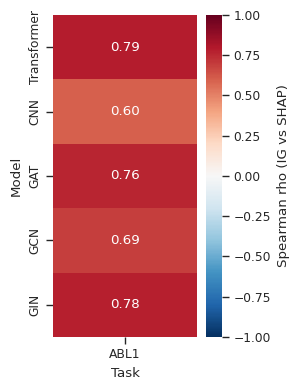

In [11]:
ig_shap_df = pair_xai_methods(fid_df).assign(task=DATASET)
ig_shap_corr_df = compute_correlation_summary(ig_shap_df, ['task', 'model'], 'normalized_fid_ig', 'normalized_fid_shap')
plot_correlation_heatmap(ig_shap_corr_df, output_dir=OUTPUT_DIR)
ig_shap_corr_df

### KernelSHAP vs SHAP agreement

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,ABL1,CNN,685,0.300570,9.062460e-16,0.281016,6.732928e-14
1,ABL1,GAT,685,0.292129,6.064251e-15,0.334444,2.306846e-19
2,ABL1,GCN,685,0.359744,2.343020e-22,0.352592,1.752935e-21
3,ABL1,GIN,685,0.414786,7.287242e-30,0.427185,9.292791e-32
4,ABL1,Transformer,685,0.403986,2.815041e-28,0.440379,7.307145e-34


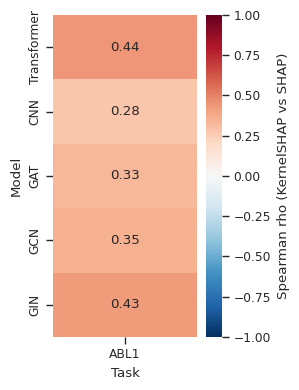

In [12]:
kernel_shap_df = pair_xai_methods(fid_df, method_a='kernel_shap', label_a='kernel_shap').assign(task=DATASET)
kernel_shap_corr_df = compute_correlation_summary(
    kernel_shap_df, ['task', 'model'], 'normalized_fid_kernel_shap', 'normalized_fid_shap'
)
plot_correlation_heatmap(kernel_shap_corr_df, cbar_label='Spearman rho (KernelSHAP vs SHAP)', output_dir=OUTPUT_DIR,
                         filename='kernel_shap_vs_shap_correlation_heatmap')
kernel_shap_corr_df

## Model comparison

In [13]:
#comparison_csv = BASE_DIR / 'multi_model_comparison.csv'
#format_multi_model_comparison_table(comparison_csv)

In [14]:
# print(format_latex_model_comparison_table(
#     comparison_csv,
#     caption='Model performance for the ABL1 task.',
#     label='tab:model_perf_abl1',
# ))